In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px

In [2]:
df_c = pd.read_csv('customers_clean.csv')

In [3]:
df_c.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    5000 non-null   str  
 1   customer_name  5000 non-null   str  
 2   gender         5000 non-null   str  
 3   age            5000 non-null   int64
 4   state          5000 non-null   str  
 5   city           5000 non-null   str  
 6   signup_date    5000 non-null   str  
dtypes: int64(1), str(6)
memory usage: 517.9 KB


In [4]:
df_c['signup_date'] = pd.to_datetime(df_c['signup_date'])

In [5]:
df_c.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customer_id    5000 non-null   str           
 1   customer_name  5000 non-null   str           
 2   gender         5000 non-null   str           
 3   age            5000 non-null   int64         
 4   state          5000 non-null   str           
 5   city           5000 non-null   str           
 6   signup_date    5000 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 469.1 KB


In [6]:
df_o = pd.read_csv('orders_clean.csv')

In [7]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       29951 non-null  str    
 1   customer_id    29065 non-null  str    
 2   order_date     29951 non-null  str    
 3   product_id     29951 non-null  str    
 4   seller_id      29951 non-null  str    
 5   quantity       29951 non-null  int64  
 6   list_price     29951 non-null  float64
 7   discount_pct   29951 non-null  int64  
 8   sales_amount   29951 non-null  float64
 9   cost_amount    29951 non-null  float64
 10  profit         29951 non-null  float64
 11  order_status   29951 non-null  str    
 12  shipping_days  29951 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 4.2 MB


In [8]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [9]:
df_o['shipping_days'] = df_o['shipping_days'].astype(int)

In [21]:
# 1. repeat customers.  how many customers ordered again, with same customer_id.

In [22]:
df_o['order_status'].unique()

<ArrowStringArray>
['Delivered', 'Cancelled', 'Shipped']
Length: 3, dtype: str

In [23]:
# keeping only real purchases.

rp = df_o[df_o['order_status'] != 'Cancelled']
rp = rp.dropna(subset = ['customer_id'])

In [26]:
rp.shape

(26951, 13)

In [32]:
count = rp.groupby('customer_id')['order_id'].count()
total = len(count)
repeat = (count>1).sum()

print('Total Customers :', total)
print('Repeat Customers :', repeat)
print('Repeat % Buyer :', round(repeat / total*100, 1))

Total Customers : 4581
Repeat Customers : 3719
Repeat % Buyer : 81.2


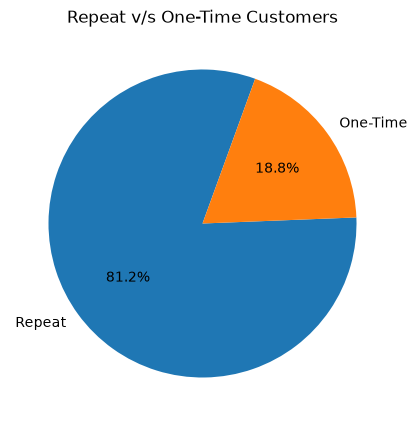

In [48]:
plt.figure(figsize = (5,5))
plt.pie([repeat, total - repeat], labels = ['Repeat', 'One-Time'], autopct = '%1.1f%%', startangle = 70 )
plt.title('Repeat v/s One-Time Customers')
plt.show()

About 8 out of 10 customers (81.2%) came back and bought again.
Only 2 out of 10 (18.8%) bought just one time.
People like shopping here, so most of them return.

In [49]:
print(count.describe())

count    4581.000000
mean        5.883213
std        33.055420
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max      1805.000000
Name: order_id, dtype: float64


In [50]:
# so if we have to count how many customers are buying how many orders.
# [0,1,3,10,1000]

In [51]:
# 2. how many orders do customes make?

In [74]:
groups = pd.cut(count, [0,1,3,10,1000], labels = ['1-Order(One-Time)', '2-3 Orders(Occasional)', '4-10 Orders(Regular)', '11+ Orders(Loyal)'])
pct = groups.value_counts(normalize=True).sort_index()*100

In [75]:
print(pct)

order_id
1-Order(One-Time)         18.820961
2-3 Orders(Occasional)    38.515284
4-10 Orders(Regular)      35.414847
11+ Orders(Loyal)          7.248908
Name: proportion, dtype: float64


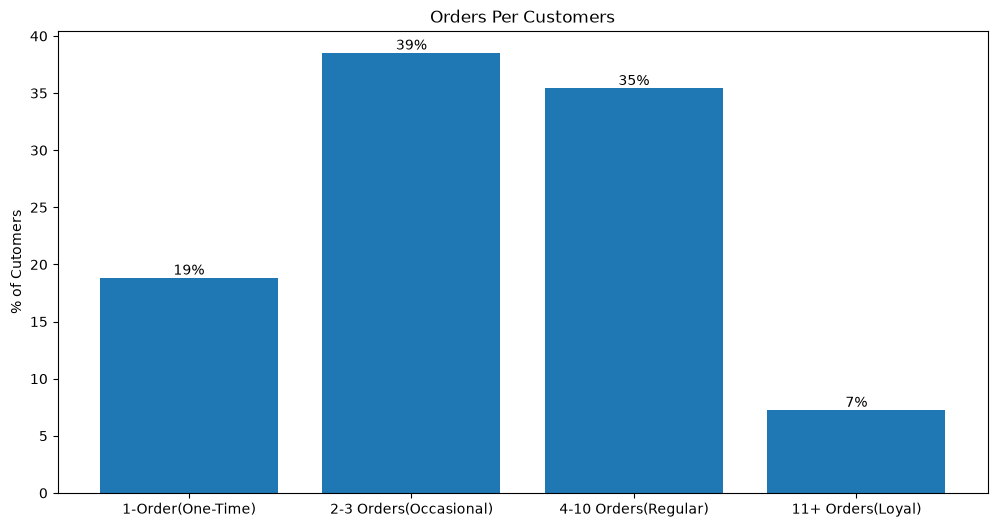

In [98]:
plt.figure(figsize = (12,6))
bar = plt.bar(pct.index, pct.values)
plt.bar_label(bar, fmt = ('%.0f%%'))
plt.title('Orders Per Customers')
plt.ylabel('% of Cutomers')
plt.show()

19% bought 1 time.
39% bought 2 or 3 times.
37% bought 4 to 10 times.
7% bought more than 10 times.
Most customers buy a few times. Only a small group are super fans. If we could move the 2–3 time buyers up to 4–10, we would earn a lot more.

In [91]:
df_o.columns

Index(['order_id', 'customer_id', 'order_date', 'product_id', 'seller_id',
       'quantity', 'list_price', 'discount_pct', 'sales_amount', 'cost_amount',
       'profit', 'order_status', 'shipping_days'],
      dtype='str')

In [92]:
# How Much Money Repeat Customer Bring

In [93]:
rp.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4
5,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2


In [95]:
money = rp.groupby('customer_id')['sales_amount'].sum()
repeat_money = money[count>1].sum()

In [104]:
print(rp['sales_amount'].sum())

135341554.65


In [102]:
print(repeat_money)

130862884.18


In [106]:
130862884.18/135341554.65*100

96.69083861081538

In [96]:
print('Repeat Customers Revenue%', round(repeat_money/money.sum()*100,1))

Repeat Customers Revenue% 96.7


Text(0.5, 1.0, 'Revenue From Repeat vs One-Time Customers')

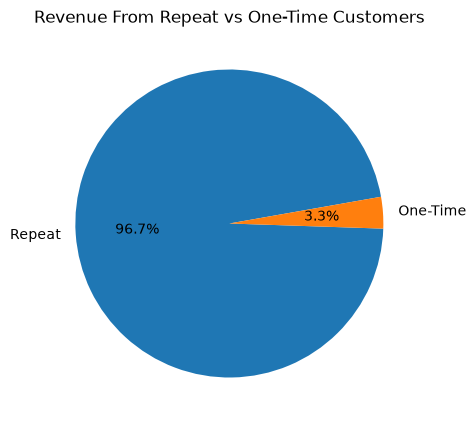

In [101]:
rev = money[count>1].sum(), money[count == 1].sum()
plt.figure(figsize = (5,5))
plt.pie(rev, labels =['Repeat', 'One-Time'], autopct = '%0.1f%%', startangle = 10 )
plt.title('Revenue From Repeat vs One-Time Customers')

Customers who came back gave us 96.7% of the money.
Customers who bought only once gave just 3.3%.
The customers who come back are worth much more than new ones. We should look after them.

In [108]:
# How fequently they repeat?

In [112]:
rp = rp.sort_values(['customer_id','order_date'])
rp['gap'] = rp.groupby('customer_id')['order_date'].diff().dt.days

In [124]:
days = rp.groupby('customer_id')['gap'].first().dropna()

In [147]:
mday = days.median().astype(int)

In [179]:
days.describe()

count    3719.000000
mean      168.322667
std       172.853448
min         0.000000
25%        32.000000
50%       116.000000
75%       253.000000
max       940.000000
Name: gap, dtype: float64

In [148]:
mday

np.int64(116)

In [130]:
print('median days To Order',days.median())

median days To Order 116.0


In [188]:
print('% Ordering Again Within 120 Days : ',round((days <= 120).sum()/ total *100,1) )

% Ordering Again Within 120 Days :  41.4


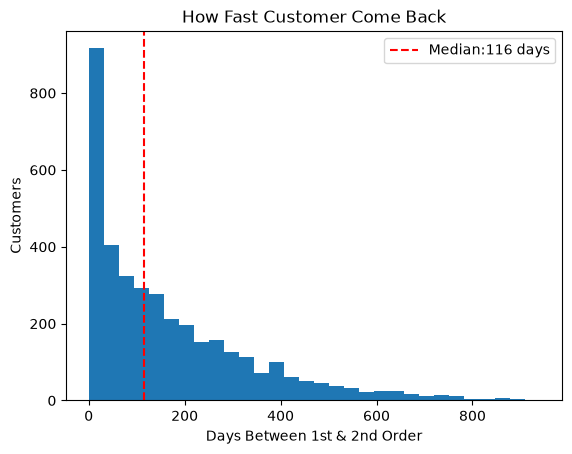

In [189]:
plt.figure()
plt.hist(days, bins = 30)
plt.axvline(mday, linestyle= '--' ,color = 'red',label = f'Median:{mday} days')
plt.title('How Fast Customer Come Back')
plt.xlabel('Days Between 1st & 2nd Order')
plt.ylabel('Customers')
plt.legend()
plt.show()

The middle customer bought a second time after about 116 days (about 4 months).
41.4% come back in 120 days or 4months. A few take more than 2 years.
Around day 3 & 1/2 months, we can send a reminder or a small gift, so customers return even faster.

In [180]:
# Retention by year of first order

In [157]:
first_year = rp.groupby('customer_id')['order_date'].min().dt.year
is_repeat = count>1
print(is_repeat.groupby(first_year).mean().mul(100).round(1))

order_date
2022    93.3
2023    88.9
2024    71.1
Name: order_id, dtype: float64


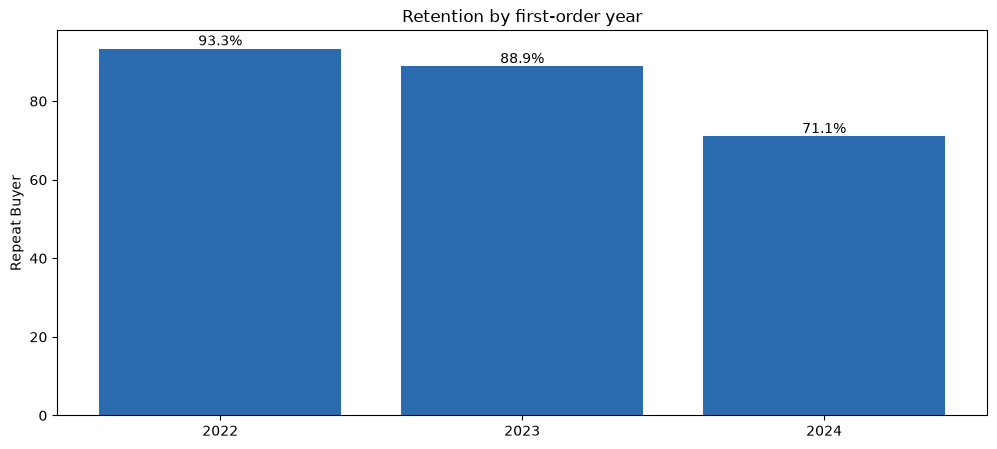

In [176]:
rate = (count > 1).groupby(first_year).mean()*100

plt.figure(figsize= (12,5))
bars = plt.bar(rate.index.astype(str), rate.values, color = '#2b6cb0')
plt.bar_label(bars, fmt= '%.1f%%')
plt.title('Retention by first-order year')
plt.ylabel('Repeat Buyer')
plt.show()

Customers who joined in 2022 came back 93.3% of the time, 
2023 customers 88.9% and 
2024 customers 71.1%.
The 2024 bar is lower only because those customers have had less time to come back. It does not mean they like us less.

In [190]:
end = rp['order_date'].max()

df = pd.DataFrame({'first':rp.groupby('customer_id')['order_date'].min(),
                   'gap':  rp.groupby('customer_id')['gap'].first()})   # blank if never came back
df['year'] = df['first'].dt.year

fair = df[df['first'] <= end - pd.Timedelta(days=116)].copy()   # everyone had 116 days to come back
fair['back_in_90'] = fair['gap'] <= 116

print((fair.groupby('year')['back_in_90'].mean() * 100).round(1))

year
2022    36.2
2023    34.6
2024    35.3
Name: back_in_90, dtype: float64


In [181]:
rp.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days,gap
13501,O027400,C00001,2023-04-16,P0419,S0164,3,1469.72,15,3747.79,2496.69,1251.10,Delivered,9,NaN
19376,O012247,C00001,2023-05-09,P0518,S0130,2,160.37,15,272.63,258.18,14.45,Delivered,9,23.0
16170,O003575,C00001,2023-08-12,P0088,S0120,2,341.71,15,580.91,386.20,194.71,Delivered,8,95.0
6852,O010469,C00002,2023-06-29,P0122,S0145,1,24034.78,0,24034.78,19567.21,4467.57,Delivered,8,NaN
3343,O008413,C00002,2023-09-25,P0028,S0018,4,2519.75,0,10079.00,5029.84,5049.16,Delivered,6,88.0


In [182]:
rp['order_date'].describe()

count                         26951
mean     2024-04-28 06:53:33.031056
min             2022-01-05 00:00:00
25%             2023-10-22 00:00:00
50%             2024-07-26 00:00:00
75%             2024-12-31 00:00:00
max             2024-12-31 00:00:00
Name: order_date, dtype: object

### What we should do?